In [ ]:
!nvidia-smi

Tue Oct 13 19:02:47 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

dataset_path = "/content/drive/MyDrive/tomato final dataset"

print("Dataset exists:", os.path.exists(dataset_path))

if os.path.exists(dataset_path):
    print("Contents:", os.listdir(dataset_path))

Dataset exists: True
Contents: ['README.roboflow.txt', 'README.dataset.txt', 'train', 'test', 'valid']


In [ ]:
import os

dataset_path = "/content/drive/MyDrive/tomato final dataset"

if not os.path.exists(dataset_path):
    raise FileNotFoundError(
        f"Dataset not found: {dataset_path}"
    )

print("Dataset exists:", True)

print("\nMain contents:")
print(os.listdir(dataset_path))

for split in ["train", "valid", "test"]:

    split_path = os.path.join(
        dataset_path,
        split
    )

    print(f"\n===== {split.upper()} =====")

    if os.path.exists(split_path):
        print(os.listdir(split_path))

    else:
        raise FileNotFoundError(
            f"Missing split folder: {split_path}"
        )

Dataset exists: True

Main contents:
['README.roboflow.txt', 'README.dataset.txt', 'train', 'test', 'valid']

===== TRAIN =====
['_annotations.coco.json', 'seeding', 'fruiting', 'flowering', 'developing']

===== VALID =====
['_annotations.coco.json', 'seeding', 'fruiting', 'developing', 'flowering']

===== TEST =====
['_annotations.coco.json', 'seeding', 'flowering', 'developing', 'fruiting']


In [ ]:
image_extensions = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
)

for split in [
    "train",
    "valid",
    "test"
]:

    split_path = os.path.join(
        dataset_path,
        split
    )

    print(
        f"\n===== {split.upper()} IMAGE COUNTS ====="
    )

    total = 0

    for class_name in sorted(
        os.listdir(split_path)
    ):

        class_path = os.path.join(
            split_path,
            class_name
        )

        if os.path.isdir(class_path):

            count = len([
                f
                for f in os.listdir(class_path)
                if f.lower().endswith(
                    image_extensions
                )
            ])

            print(
                f"{class_name}: {count}"
            )

            total += count

    print(
        "Total:",
        total
    )


===== TRAIN IMAGE COUNTS =====
developing: 142
flowering: 210
fruiting: 71
seeding: 264
Total: 687

===== VALID IMAGE COUNTS =====
developing: 20
flowering: 30
fruiting: 9
seeding: 76
Total: 135

===== TEST IMAGE COUNTS =====
developing: 41
flowering: 60
fruiting: 21
seeding: 38
Total: 160


In [ ]:
import torch

print(
    "PyTorch:",
    torch.__version__
)

print(
    "CUDA available:",
    torch.cuda.is_available()
)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

else:

    raise RuntimeError(
        "GPU not detected. "
        "Select Runtime > Change runtime type > T4 GPU."
    )

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
import os
import copy
import time
import random
import shutil
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import (
    Dataset,
    DataLoader
)

from torchvision import (
    transforms,
    models
)

from torchvision.models.segmentation import (
    deeplabv3_resnet50
)

from PIL import Image

from sklearn.model_selection import (
    StratifiedKFold
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tqdm.auto import tqdm

print("Imports completed successfully")

Imports completed successfully


In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print(
    "Device:",
    device
)

Device: cuda


In [ ]:
DATASET_PATH = (
    "/content/drive/MyDrive/"
    "tomato final dataset"
)

TRAIN_DIR = os.path.join(
    DATASET_PATH,
    "train"
)

VALID_DIR = os.path.join(
    DATASET_PATH,
    "valid"
)

TEST_DIR = os.path.join(
    DATASET_PATH,
    "test"
)

CLASS_NAMES = [
    "developing",
    "flowering",
    "fruiting",
    "seeding"
]

NUM_CLASSES = len(
    CLASS_NAMES
)

IMAGE_SIZE = 224

BATCH_SIZE = 32

NUM_EPOCHS = 20

LEARNING_RATE = 1e-4

# T4 GPU
NUM_WORKERS = 2

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]

# =====================================
# DEEPLABV3 + RESNET101 OUTPUT
# =====================================

PIPELINE_ROOT = (
    "/content/drive/MyDrive/"
    "tomato_research/"
    "deeplabv3_pipeline"
)

OUTPUT_DIR = os.path.join(
    PIPELINE_ROOT,
    "resnet101_5fold_cv"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

print(
    "Dataset exists:",
    os.path.exists(DATASET_PATH)
)

print(
    "Pipeline root:",
    PIPELINE_ROOT
)

print(
    "Output directory:",
    OUTPUT_DIR
)

Dataset exists: True
Pipeline root: /content/drive/MyDrive/tomato_research/deeplabv3_pipeline
Output directory: /content/drive/MyDrive/tomato_research/deeplabv3_pipeline/resnet101_5fold_cv


In [ ]:
for split in [
    "train",
    "valid",
    "test"
]:

    split_path = os.path.join(
        DATASET_PATH,
        split
    )

    print(
        f"\n===== {split.upper()} IMAGE COUNTS ====="
    )

    total = 0

    for class_name in CLASS_NAMES:

        class_path = os.path.join(
            split_path,
            class_name
        )

        if not os.path.exists(class_path):

            raise FileNotFoundError(
                f"Missing class folder: {class_path}"
            )

        files = [
            f
            for f in os.listdir(class_path)
            if f.lower().endswith(
                image_extensions
            )
        ]

        print(
            f"{class_name}: {len(files)}"
        )

        total += len(files)

    print(
        "Total:",
        total
    )


===== TRAIN IMAGE COUNTS =====
developing: 142
flowering: 210
fruiting: 71
seeding: 264
Total: 687

===== VALID IMAGE COUNTS =====
developing: 20
flowering: 30
fruiting: 9
seeding: 76
Total: 135

===== TEST IMAGE COUNTS =====
developing: 41
flowering: 60
fruiting: 21
seeding: 38
Total: 160


In [ ]:

DEEPLAB_CHECKPOINT = (
    "/content/drive/MyDrive/"
    "tomato_research/"
    "deeplabv3_pipeline/"
    "checkpoints_segmentation/"
    "deeplabv3_leaf_seg_best.pt"
)

print(
    "DeepLabV3 checkpoint path:"
)

print(
    DEEPLAB_CHECKPOINT
)

DeepLabV3 checkpoint path:
/content/drive/MyDrive/tomato_research/deeplabv3_pipeline/checkpoints_segmentation/deeplabv3_leaf_seg_best.pt


In [ ]:
print(
    "DeepLabV3 checkpoint exists:",
    os.path.exists(
        DEEPLAB_CHECKPOINT
    )
)

if not os.path.exists(
    DEEPLAB_CHECKPOINT
):

    raise FileNotFoundError(
        "DeepLabV3 checkpoint was not found.\n"
        f"Expected path:\n{DEEPLAB_CHECKPOINT}"
    )

print(
    "File size:",
    os.path.getsize(
        DEEPLAB_CHECKPOINT
    ),
    "bytes"
)

DeepLabV3 checkpoint exists: True
File size: 168339118 bytes


In [ ]:
checkpoint = torch.load(
    DEEPLAB_CHECKPOINT,
    map_location=device,
    weights_only=False
)

print(
    "Checkpoint type:",
    type(checkpoint)
)

if (
    isinstance(checkpoint, dict)
    and "model_state_dict" in checkpoint
):

    state_dict = checkpoint[
        "model_state_dict"
    ]

elif (
    isinstance(checkpoint, dict)
    and "state_dict" in checkpoint
):

    state_dict = checkpoint[
        "state_dict"
    ]

else:

    state_dict = checkpoint


# --------------------------------------
# Remove DataParallel prefix if present
# --------------------------------------

clean_state_dict = {}

for key, value in state_dict.items():

    if key.startswith(
        "module."
    ):

        new_key = key[
            len("module.") :
        ]

    else:

        new_key = key

    clean_state_dict[
        new_key
    ] = value

state_dict = clean_state_dict


# --------------------------------------
# Detect auxiliary classifier
# --------------------------------------

HAS_AUX_CLASSIFIER = any(
    key.startswith(
        "aux_classifier."
    )
    for key in state_dict.keys()
)

print(
    "Auxiliary classifier in checkpoint:",
    HAS_AUX_CLASSIFIER
)


def build_deeplab_model():

    model = deeplabv3_resnet50(
        weights=None,
        weights_backbone=None,
        aux_loss=HAS_AUX_CLASSIFIER
    )

    # Background / foreground
    model.classifier[4] = nn.Conv2d(
        256,
        2,
        kernel_size=1
    )

    if (
        HAS_AUX_CLASSIFIER
        and model.aux_classifier is not None
    ):

        model.aux_classifier[4] = nn.Conv2d(
            256,
            2,
            kernel_size=1
        )

    return model.to(
        device
    )


print(
    "DeepLabV3 architecture defined successfully"
)

Checkpoint type: <class 'dict'>
Auxiliary classifier in checkpoint: True
DeepLabV3 architecture defined successfully


In [ ]:
deeplab_model = build_deeplab_model()

deeplab_model.load_state_dict(
    state_dict,
    strict=True
)

deeplab_model.eval()

for parameter in (
    deeplab_model.parameters()
):

    parameter.requires_grad = False

print(
    "DeepLabV3 loaded successfully"
)

if isinstance(
    checkpoint,
    dict
):

    if "val_iou" in checkpoint:

        print(
            "Saved validation IoU:",
            checkpoint["val_iou"]
        )

    if "epoch" in checkpoint:

        print(
            "Saved best epoch:",
            checkpoint["epoch"]
        )

DeepLabV3 loaded successfully
Saved validation IoU: 0.7956297490956673
Saved best epoch: 15


In [ ]:
crop_transform = transforms.Compose([
    transforms.Resize(
        int(
            IMAGE_SIZE * 1.14
        )
    ),

    transforms.CenterCrop(
        IMAGE_SIZE
    ),
])

to_tensor = transforms.ToTensor()

normalize = transforms.Normalize(
    IMAGENET_MEAN,
    IMAGENET_STD
)

print(
    "Preprocessing ready"
)

print(
    "Image size:",
    IMAGE_SIZE
)

Preprocessing ready
Image size: 224


In [ ]:
@torch.no_grad()
def create_masked_image(
    image_path
):

    img = Image.open(
        image_path
    ).convert(
        "RGB"
    )

    img_crop = crop_transform(
        img
    )

    raw_tensor = to_tensor(
        img_crop
    )

    deeplab_input = normalize(
        raw_tensor
    ).unsqueeze(
        0
    ).to(
        device
    )

    output = deeplab_model(
        deeplab_input
    )

    logits = output[
        "out"
    ]

    # 0 = background
    # 1 = plant / leaf-focused foreground
    mask = torch.argmax(
        logits,
        dim=1,
        keepdim=True
    ).float()

    # ==================================
    # LEAF PIXEL FRACTION
    # ==================================

    foreground_pixels = (
        mask.sum().item()
    )

    total_pixels = (
        mask.numel()
    )

    lpf = (
        foreground_pixels
        / total_pixels
    )

    # ==================================
    # Background removal
    # ==================================

    masked_tensor = (
        raw_tensor
        .unsqueeze(0)
        .to(device)
        * mask
    ).squeeze(
        0
    ).cpu()

    return (
        img_crop,
        mask.squeeze().cpu(),
        masked_tensor,
        lpf
    )

In [ ]:
developing_test_dir = os.path.join(
    TEST_DIR,
    "developing"
)

sample_files = sorted([
    f
    for f in os.listdir(
        developing_test_dir
    )
    if f.lower().endswith(
        image_extensions
    )
])

sample_path = os.path.join(
    developing_test_dir,
    sample_files[0]
)

(
    original_img,
    predicted_mask,
    masked_img,
    sample_lpf
) = create_masked_image(
    sample_path
)

print(
    "Sample:",
    sample_path
)

print(
    "Original size:",
    original_img.size
)

print(
    "Mask shape:",
    predicted_mask.shape
)

print(
    "Unique mask values:",
    torch.unique(
        predicted_mask
    ).tolist()
)

print(
    "LPF:",
    round(
        sample_lpf,
        4
    )
)

print(
    "LPF percentage:",
    round(
        sample_lpf * 100,
        2
    ),
    "%"
)

Sample: /content/drive/MyDrive/tomato final dataset/test/developing/photo_dev (103)_jpg.rf.RWQrfFCEy7p25IXgGCmv.jpg
Original size: (224, 224)
Mask shape: torch.Size([224, 224])
Unique mask values: [0.0, 1.0]
LPF: 0.5017
LPF percentage: 50.17 %


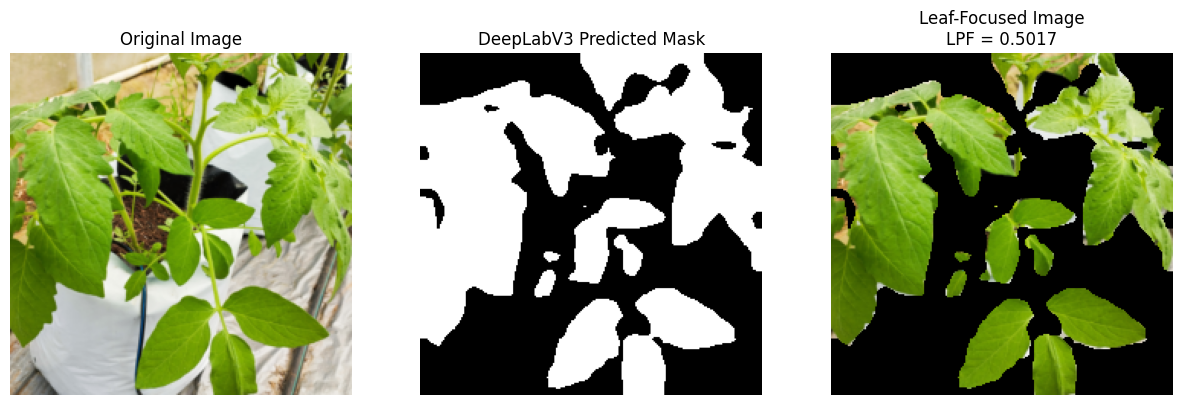

In [ ]:
plt.figure(
    figsize=(15, 5)
)

plt.subplot(
    1,
    3,
    1
)

plt.imshow(
    original_img
)

plt.title(
    "Original Image"
)

plt.axis(
    "off"
)


plt.subplot(
    1,
    3,
    2
)

plt.imshow(
    predicted_mask,
    cmap="gray"
)

plt.title(
    "DeepLabV3 Predicted Mask"
)

plt.axis(
    "off"
)


plt.subplot(
    1,
    3,
    3
)

plt.imshow(
    masked_img.permute(
        1,
        2,
        0
    )
)

plt.title(
    f"Leaf-Focused Image\n"
    f"LPF = {sample_lpf:.4f}"
)

plt.axis(
    "off"
)

plt.show()

In [ ]:
LOCAL_MASKED_DIR = (
    "/content/"
    "data_deeplabv3_masked_resnet101"
)

os.makedirs(
    LOCAL_MASKED_DIR,
    exist_ok=True
)

print(
    "DeepLabV3 masked dataset "
    "will be stored at:"
)

print(
    LOCAL_MASKED_DIR
)

DeepLabV3 masked dataset will be stored at:
/content/data_deeplabv3_masked_resnet101


In [ ]:
@torch.no_grad()
def mask_and_save(
    src_path,
    dst_path
):

    img = Image.open(
        src_path
    ).convert(
        "RGB"
    )

    img_crop = crop_transform(
        img
    )

    raw01 = to_tensor(
        img_crop
    )

    deeplab_input = normalize(
        raw01
    ).unsqueeze(
        0
    ).to(
        device
    )

    output = deeplab_model(
        deeplab_input
    )

    logits = output[
        "out"
    ]

    pred_mask = torch.argmax(
        logits,
        dim=1,
        keepdim=True
    ).float()


    # ==================================
    # LPF
    # ==================================

    foreground_pixels = (
        pred_mask
        .sum()
        .item()
    )

    total_pixels = (
        pred_mask
        .numel()
    )

    lpf = (
        foreground_pixels
        / total_pixels
    )


    # ==================================
    # Apply foreground mask
    # ==================================

    masked = (
        raw01
        .unsqueeze(0)
        .to(device)
        * pred_mask
    ).squeeze(
        0
    ).cpu()


    masked_img = (
        transforms
        .ToPILImage()(
            masked
        )
    )


    os.makedirs(
        os.path.dirname(
            dst_path
        ),
        exist_ok=True
    )


    masked_img.save(
        dst_path,
        quality=95
    )


    return lpf

In [ ]:
SPLITS = [
    "train",
    "valid",
    "test"
]

n_done = 0

lpf_records = []


for split in SPLITS:

    print(
        f"\nProcessing {split.upper()}..."
    )


    for stage in CLASS_NAMES:

        src_dir = os.path.join(
            DATASET_PATH,
            split,
            stage
        )

        dst_dir = os.path.join(
            LOCAL_MASKED_DIR,
            split,
            stage
        )

        os.makedirs(
            dst_dir,
            exist_ok=True
        )


        filenames = [
            f
            for f in sorted(
                os.listdir(
                    src_dir
                )
            )
            if f.lower().endswith(
                image_extensions
            )
        ]


        for fname in tqdm(
            filenames,
            desc=f"{split}/{stage}"
        ):

            src_path = os.path.join(
                src_dir,
                fname
            )

            dst_path = os.path.join(
                dst_dir,
                fname
            )


            lpf = mask_and_save(
                src_path,
                dst_path
            )


            lpf_records.append({

                "image":
                    fname,

                "split":
                    split,

                "stage":
                    stage,

                "LPF":
                    lpf,

                "LPF_percent":
                    lpf * 100
            })


            n_done += 1


print(
    "\nCompleted."
)

print(
    "Total DeepLabV3 masked images generated:",
    n_done
)


# ==================================
# Save LPF values
# ==================================

lpf_df = pd.DataFrame(
    lpf_records
)


LPF_CSV_PATH = os.path.join(
    OUTPUT_DIR,
    "deeplabv3_resnet101_lpf_values.csv"
)


lpf_df.to_csv(
    LPF_CSV_PATH,
    index=False
)


print(
    "\nLPF values saved to:"
)

print(
    LPF_CSV_PATH
)


display(
    lpf_df.head()
)


Processing TRAIN...


train/developing:   0%|          | 0/142 [00:00<?, ?it/s]

train/flowering:   0%|          | 0/210 [00:00<?, ?it/s]

train/fruiting:   0%|          | 0/71 [00:00<?, ?it/s]

train/seeding:   0%|          | 0/264 [00:00<?, ?it/s]

...

test/flowering:   0%|          | 0/60 [00:00<?, ?it/s]

test/fruiting:   0%|          | 0/21 [00:00<?, ?it/s]

test/seeding:   0%|          | 0/38 [00:00<?, ?it/s]


Completed.
Total DeepLabV3 masked images generated: 982

LPF values saved to:
/content/drive/MyDrive/tomato_research/deeplabv3_pipeline/resnet101_5fold_cv/deeplabv3_resnet101_lpf_values.csv


,image,split,stage,LPF,LPF_percent
0,photo_dev (1)_jpg.rf.sUf4QjGbVQOtVEYcpDdQ.jpg,train,developing,0.311902,31.190210
1,photo_dev (100)_jpg.rf.RNqLRQIHCuBC2oZtVEel.jpg,train,developing,0.449518,44.951770
2,photo_dev (101)_jpg.rf.eSiKk2GlXqRFY6Oa9neE.jpg,train,developing,0.297393,29.739318
3,photo_dev (102)_jpg.rf.pMCmIOLoDI2I3cRd2kvu.jpg,train,developing,0.234574,23.457430
4,photo_dev (104)_jpg.rf.lMh1PECQE9VPBYX3M6bH.jpg,train,developing,0.448840,44.884008


In [ ]:
stage_lpf_summary = (
    lpf_df
    .groupby(
        "stage"
    )[
        "LPF"
    ]
    .agg([
        "count",
        "mean",
        "std",
        "min",
        "max"
    ])
    .reset_index()
)


stage_lpf_summary[
    "mean_percent"
] = (
    stage_lpf_summary[
        "mean"
    ]
    * 100
)


stage_lpf_summary[
    "std_percent"
] = (
    stage_lpf_summary[
        "std"
    ]
    * 100
)


print(
    "Stage-wise LPF summary"
)


display(
    stage_lpf_summary
)


LPF_SUMMARY_PATH = os.path.join(
    OUTPUT_DIR,
    "deeplabv3_resnet101_lpf_stage_summary.csv"
)


stage_lpf_summary.to_csv(
    LPF_SUMMARY_PATH,
    index=False
)


print(
    "LPF summary saved to:"
)

print(
    LPF_SUMMARY_PATH
)

Stage-wise LPF summary


,stage,count,mean,std,min,max,mean_percent,std_percent
0,developing,203,0.342439,0.105962,0.049007,0.608080,34.243895,10.596198
1,flowering,300,0.254661,0.083344,0.059770,0.501953,25.466086,8.334386
2,fruiting,101,0.189728,0.058833,0.068021,0.392658,18.972780,5.883267
3,seeding,378,0.050196,0.033695,0.004763,0.251754,5.019585,3.369526


LPF summary saved to:
/content/drive/MyDrive/tomato_research/deeplabv3_pipeline/resnet101_5fold_cv/deeplabv3_resnet101_lpf_stage_summary.csv


In [ ]:
masked_counts = {}


for split in [
    "train",
    "valid",
    "test"
]:

    print(
        f"\n===== "
        f"{split.upper()} "
        f"MASKED IMAGE COUNTS ====="
    )

    total = 0


    for class_name in CLASS_NAMES:

        class_path = os.path.join(
            LOCAL_MASKED_DIR,
            split,
            class_name
        )

        files = [
            f
            for f in os.listdir(
                class_path
            )
            if f.lower().endswith(
                image_extensions
            )
        ]

        count = len(
            files
        )

        print(
            f"{class_name}: {count}"
        )

        total += count


    masked_counts[
        split
    ] = total

    print(
        "Total:",
        total
    )


assert masked_counts[
    "train"
] == 687

assert masked_counts[
    "valid"
] == 135

assert masked_counts[
    "test"
] == 160


print(
    "\nAll masked-image counts are correct."
)


===== TRAIN MASKED IMAGE COUNTS =====
developing: 142
flowering: 210
fruiting: 71
seeding: 264
Total: 687

===== VALID MASKED IMAGE COUNTS =====
developing: 20
flowering: 30
fruiting: 9
seeding: 76
Total: 135

===== TEST MASKED IMAGE COUNTS =====
developing: 41
flowering: 60
fruiting: 21
seeding: 38
Total: 160

All masked-image counts are correct.


In [ ]:
class_to_idx = {
    class_name: idx
    for idx, class_name
    in enumerate(
        CLASS_NAMES
    )
}

print(
    class_to_idx
)

{'developing': 0, 'flowering': 1, 'fruiting': 2, 'seeding': 3}


In [ ]:
cv_samples = []
cv_labels = []


for split in [
    "train",
    "valid"
]:

    for class_name in CLASS_NAMES:

        class_dir = os.path.join(
            LOCAL_MASKED_DIR,
            split,
            class_name
        )


        files = [
            f
            for f in sorted(
                os.listdir(
                    class_dir
                )
            )
            if f.lower().endswith(
                image_extensions
            )
        ]


        for fname in files:

            path = os.path.join(
                class_dir,
                fname
            )


            cv_samples.append(
                path
            )


            cv_labels.append(
                class_to_idx[
                    class_name
                ]
            )


cv_samples = np.array(
    cv_samples
)

cv_labels = np.array(
    cv_labels
)


print(
    "Total CV images:",
    len(cv_samples)
)

print(
    "Total CV labels:",
    len(cv_labels)
)


assert len(
    cv_samples
) == 822

assert len(
    cv_labels
) == 822

Total CV images: 822
Total CV labels: 822


In [ ]:
for class_name, idx in (
    class_to_idx.items()
):

    count = np.sum(
        cv_labels == idx
    )

    print(
        f"{class_name}: {count}"
    )

developing: 162
flowering: 240
fruiting: 80
seeding: 340


In [ ]:
test_samples = []
test_labels = []


for class_name in CLASS_NAMES:

    class_dir = os.path.join(
        LOCAL_MASKED_DIR,
        "test",
        class_name
    )


    files = [
        f
        for f in sorted(
            os.listdir(
                class_dir
            )
        )
        if f.lower().endswith(
            image_extensions
        )
    ]


    for fname in files:

        test_samples.append(
            os.path.join(
                class_dir,
                fname
            )
        )

        test_labels.append(
            class_to_idx[
                class_name
            ]
        )


test_samples = np.array(
    test_samples
)

test_labels = np.array(
    test_labels
)


print(
    "Held-out masked test images:",
    len(test_samples)
)


assert len(
    test_samples
) == 160

Held-out masked test images: 160


In [ ]:
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        IMAGE_SIZE,
        scale=(0.8, 1.0)
    ),

    transforms.RandomHorizontalFlip(),

    transforms.RandomRotation(
        15
    ),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD
    )
])


# Keep same as previous matched experiments
eval_transform = transforms.Compose([
    transforms.Resize(
        int(
            IMAGE_SIZE * 1.14
        )
    ),

    transforms.CenterCrop(
        IMAGE_SIZE
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD
    )
])


print(
    "Classifier transforms ready"
)

Classifier transforms ready


In [ ]:
class TomatoMaskedDataset(
    Dataset
):

    def __init__(
        self,
        paths,
        labels,
        transform=None
    ):

        self.paths = list(
            paths
        )

        self.labels = list(
            labels
        )

        self.transform = (
            transform
        )


    def __len__(
        self
    ):

        return len(
            self.paths
        )


    def __getitem__(
        self,
        idx
    ):

        image_path = (
            self.paths[idx]
        )

        image = Image.open(
            image_path
        ).convert(
            "RGB"
        )

        label = int(
            self.labels[idx]
        )


        if self.transform:

            image = (
                self.transform(
                    image
                )
            )


        return (
            image,
            label
        )

In [ ]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)


fold_splits = list(
    skf.split(
        cv_samples,
        cv_labels
    )
)


print(
    "Number of folds:",
    len(fold_splits)
)

Number of folds: 5


In [ ]:
for fold, (
    train_idx,
    val_idx
) in enumerate(
    fold_splits,
    start=1
):

    print(
        f"\nFold {fold}: "
        f"Train = {len(train_idx)}, "
        f"Validation = {len(val_idx)}"
    )


    print(
        "Validation class counts:"
    )


    for class_name, class_idx in (
        class_to_idx.items()
    ):

        count = np.sum(
            cv_labels[
                val_idx
            ] == class_idx
        )

        print(
            f"  {class_name}: {count}"
        )


Fold 1: Train = 657, Validation = 165
Validation class counts:
  developing: 33
  flowering: 48
  fruiting: 16
  seeding: 68

Fold 2: Train = 657, Validation = 165
Validation class counts:
  developing: 33
  flowering: 48
  fruiting: 16
  seeding: 68

Fold 3: Train = 658, Validation = 164
Validation class counts:
  developing: 32
  flowering: 48
  fruiting: 16
  seeding: 68

Fold 4: Train = 658, Validation = 164
Validation class counts:
  developing: 32
  flowering: 48
  fruiting: 16
  seeding: 68

Fold 5: Train = 658, Validation = 164
Validation class counts:
  developing: 32
  flowering: 48
  fruiting: 16
  seeding: 68


In [ ]:
raw_test_samples = []
raw_test_labels = []


for class_name in CLASS_NAMES:

    class_dir = os.path.join(
        DATASET_PATH,
        "test",
        class_name
    )


    files = [
        f
        for f in sorted(
            os.listdir(
                class_dir
            )
        )
        if f.lower().endswith(
            image_extensions
        )
    ]


    for fname in files:

        raw_test_samples.append(
            os.path.join(
                class_dir,
                fname
            )
        )

        raw_test_labels.append(
            class_to_idx[
                class_name
            ]
        )


raw_test_samples = np.array(
    raw_test_samples
)

raw_test_labels = np.array(
    raw_test_labels
)


print(
    "Raw test images:",
    len(raw_test_samples)
)


assert len(
    raw_test_samples
) == 160

Raw test images: 160


In [ ]:
def build_resnet101():

    model = models.resnet101(
        weights=(
            models
            .ResNet101_Weights
            .IMAGENET1K_V2
        )
    )

    model.fc = nn.Linear(
        model.fc.in_features,
        NUM_CLASSES
    )

    return model.to(
        device
    )

In [ ]:
temp_model = build_resnet101()


print(
    "ResNet101 created successfully"
)


print(
    "Final layer:",
    temp_model.fc
)


del temp_model

torch.cuda.empty_cache()

Downloading: "https://download.pytorch.org/models/resnet101-cd907fc2.pth" to /root/.cache/torch/hub/checkpoints/resnet101-cd907fc2.pth


100%|██████████| 171M/171M [00:01<00:00, 117MB/s]


ResNet101 created successfully
Final layer: Linear(in_features=2048, out_features=4, bias=True)


In [ ]:
def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer
):

    model.train()

    running_loss = 0.0

    correct = 0

    total = 0


    for images, labels in tqdm(
        loader,
        leave=False
    ):

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )


        optimizer.zero_grad()


        outputs = model(
            images
        )


        loss = criterion(
            outputs,
            labels
        )


        loss.backward()


        optimizer.step()


        running_loss += (
            loss.item()
            * images.size(0)
        )


        preds = outputs.argmax(
            dim=1
        )


        correct += (
            preds == labels
        ).sum().item()


        total += (
            labels.size(0)
        )


    epoch_loss = (
        running_loss
        / total
    )


    epoch_acc = (
        correct
        / total
    )


    return (
        epoch_loss,
        epoch_acc
    )

In [ ]:
@torch.no_grad()
def evaluate_classifier(
    model,
    loader,
    criterion
):

    model.eval()

    running_loss = 0.0

    correct = 0

    total = 0

    all_labels = []

    all_preds = []


    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )


        outputs = model(
            images
        )


        loss = criterion(
            outputs,
            labels
        )


        running_loss += (
            loss.item()
            * images.size(0)
        )


        preds = outputs.argmax(
            dim=1
        )


        correct += (
            preds == labels
        ).sum().item()


        total += (
            labels.size(0)
        )


        all_labels.extend(
            labels
            .cpu()
            .numpy()
        )


        all_preds.extend(
            preds
            .cpu()
            .numpy()
        )


    epoch_loss = (
        running_loss
        / total
    )


    epoch_acc = (
        correct
        / total
    )


    return (
        epoch_loss,
        epoch_acc,
        np.array(
            all_labels
        ),
        np.array(
            all_preds
        )
    )

In [ ]:
@torch.no_grad()
def pipeline_predict(
    model,
    image_path
):

    # ==================================
    # RAW IMAGE
    # ==================================

    img = Image.open(
        image_path
    ).convert(
        "RGB"
    )


    # ==================================
    # DeepLabV3 geometry
    # ==================================

    img_crop = crop_transform(
        img
    )


    raw01 = to_tensor(
        img_crop
    )


    # ==================================
    # DeepLabV3 segmentation
    # ==================================

    deeplab_input = normalize(
        raw01
    ).unsqueeze(
        0
    ).to(
        device
    )


    output = deeplab_model(
        deeplab_input
    )


    segmentation_logits = (
        output[
            "out"
        ]
    )


    pred_mask = torch.argmax(
        segmentation_logits,
        dim=1,
        keepdim=True
    ).float()


    # ==================================
    # Remove background
    # ==================================

    masked_raw = (
        raw01
        .unsqueeze(0)
        .to(device)
        * pred_mask
    )


    # ==================================
    # ResNet101 normalization
    # ==================================

    masked_normalized = normalize(
        masked_raw.squeeze(0)
    ).unsqueeze(
        0
    )


    # ==================================
    # ResNet101 classification
    # ==================================

    classification_logits = model(
        masked_normalized
    )


    pred = (
        classification_logits
        .argmax(
            dim=1
        )
        .item()
    )


    return pred

In [ ]:
@torch.no_grad()
def evaluate_full_pipeline(
    model,
    image_paths,
    true_labels
):

    model.eval()

    deeplab_model.eval()

    predictions = []


    for image_path in tqdm(
        image_paths,
        desc=(
            "RAW → DeepLabV3 "
            "→ ResNet101 test"
        ),
        leave=False
    ):

        pred = pipeline_predict(
            model,
            image_path
        )


        predictions.append(
            pred
        )


    predictions = np.array(
        predictions
    )


    true_labels = np.array(
        true_labels
    )


    accuracy = accuracy_score(
        true_labels,
        predictions
    )


    precision = precision_score(
        true_labels,
        predictions,
        average="macro",
        zero_division=0
    )


    recall = recall_score(
        true_labels,
        predictions,
        average="macro",
        zero_division=0
    )


    f1 = f1_score(
        true_labels,
        predictions,
        average="macro",
        zero_division=0
    )


    cm = confusion_matrix(
        true_labels,
        predictions,
        labels=list(
            range(
                NUM_CLASSES
            )
        )
    )


    report = classification_report(
        true_labels,
        predictions,
        labels=list(
            range(
                NUM_CLASSES
            )
        ),
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )


    return {

        "accuracy":
            accuracy,

        "precision":
            precision,

        "recall":
            recall,

        "f1":
            f1,

        "confusion_matrix":
            cm,

        "predictions":
            predictions,

        "report":
            report
    }

In [ ]:
CHECKPOINT_DIR = os.path.join(
    OUTPUT_DIR,
    "checkpoints"
)

RESULT_DIR = os.path.join(
    OUTPUT_DIR,
    "results"
)


os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True
)

os.makedirs(
    RESULT_DIR,
    exist_ok=True
)


print(
    "Checkpoint folder:",
    CHECKPOINT_DIR
)

print(
    "Results folder:",
    RESULT_DIR
)

Checkpoint folder: /content/drive/MyDrive/tomato_research/deeplabv3_pipeline/resnet101_5fold_cv/checkpoints
Results folder: /content/drive/MyDrive/tomato_research/deeplabv3_pipeline/resnet101_5fold_cv/results


In [ ]:
all_fold_results = []

all_histories = []


criterion = nn.CrossEntropyLoss()


for fold_number, (
    train_idx,
    val_idx
) in enumerate(
    fold_splits,
    start=1
):


    print(
        "\n" + "=" * 70
    )

    print(
        f"FOLD {fold_number}/5"
    )

    print(
        "=" * 70
    )


    # =================================
    # TRAIN DATASET
    # =================================

    train_dataset = (
        TomatoMaskedDataset(
            cv_samples[
                train_idx
            ],
            cv_labels[
                train_idx
            ],
            transform=(
                train_transform
            )
        )
    )


    # =================================
    # VALIDATION DATASET
    # =================================

    val_dataset = (
        TomatoMaskedDataset(
            cv_samples[
                val_idx
            ],
            cv_labels[
                val_idx
            ],
            transform=(
                eval_transform
            )
        )
    )


    # =================================
    # T4 GPU DATALOADERS
    # =================================

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=True
    )


    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True
    )


    print(
        "Train:",
        len(
            train_dataset
        ),
        "| Validation:",
        len(
            val_dataset
        )
    )


    # =================================
    # FRESH RESNET101
    # =================================

    model = build_resnet101()


    optimizer = optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )


    scheduler = (
        optim
        .lr_scheduler
        .ReduceLROnPlateau(
            optimizer,
            mode="min",
            factor=0.5,
            patience=2
        )
    )


    best_val_acc = -1.0

    best_epoch = 0

    best_state = None

    history = []


    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        (
            "deeplabv3_"
            "resnet101_"
            f"fold_{fold_number}_"
            "best.pth"
        )
    )


    # =================================
    # TRAINING
    # =================================

    for epoch in range(
        1,
        NUM_EPOCHS + 1
    ):


        start_time = (
            time.time()
        )


        (
            train_loss,
            train_acc
        ) = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer
        )


        (
            val_loss,
            val_acc,
            val_true,
            val_pred
        ) = evaluate_classifier(
            model,
            val_loader,
            criterion
        )


        scheduler.step(
            val_loss
        )


        elapsed = (
            time.time()
            - start_time
        )


        current_lr = (
            optimizer
            .param_groups[0][
                "lr"
            ]
        )


        print(
            f"Fold {fold_number} | "
            f"Epoch "
            f"{epoch:02d}/"
            f"{NUM_EPOCHS} | "
            f"Train Loss "
            f"{train_loss:.4f} | "
            f"Train Acc "
            f"{train_acc:.4f} | "
            f"Val Loss "
            f"{val_loss:.4f} | "
            f"Val Acc "
            f"{val_acc:.4f} | "
            f"LR "
            f"{current_lr:.2e} | "
            f"{elapsed:.1f}s"
        )


        history.append({

            "fold":
                fold_number,

            "epoch":
                epoch,

            "train_loss":
                train_loss,

            "train_accuracy":
                train_acc,

            "val_loss":
                val_loss,

            "val_accuracy":
                val_acc,

            "learning_rate":
                current_lr
        })


        # =================================
        # BEST MODEL
        # =================================

        if (
            val_acc
            > best_val_acc
        ):

            best_val_acc = (
                val_acc
            )


            best_epoch = (
                epoch
            )


            best_state = (
                copy.deepcopy(
                    model.state_dict()
                )
            )


            # Save immediately for
            # interruption protection
            torch.save(
                best_state,
                checkpoint_path
            )


            print(
                f"  ✓ Best model saved "
                f"(Val Acc: "
                f"{best_val_acc:.4f})"
            )


    # =================================
    # LOAD BEST RESNET101
    # =================================

    if best_state is None:

        raise RuntimeError(
            f"No best state found "
            f"for Fold {fold_number}"
        )


    best_state = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )


    model.load_state_dict(
        best_state
    )


    print(
        f"\nBest validation accuracy: "
        f"{best_val_acc:.4f} "
        f"(epoch {best_epoch})"
    )


    # =================================
    # RAW → DEEPLABV3 → RESNET101 TEST
    # =================================

    pipeline_result = (
        evaluate_full_pipeline(
            model,
            raw_test_samples,
            raw_test_labels
        )
    )


    fold_result = {

        "fold":
            fold_number,

        "best_epoch":
            best_epoch,

        "best_val_accuracy":
            best_val_acc,

        "pipeline_accuracy":
            pipeline_result[
                "accuracy"
            ],

        "macro_precision":
            pipeline_result[
                "precision"
            ],

        "macro_recall":
            pipeline_result[
                "recall"
            ],

        "macro_f1":
            pipeline_result[
                "f1"
            ]
    }


    all_fold_results.append(
        fold_result
    )


    all_histories.extend(
        history
    )


    # =================================
    # CONFUSION MATRIX
    # =================================

    np.save(
        os.path.join(
            RESULT_DIR,
            (
                f"fold_{fold_number}_"
                "confusion_matrix.npy"
            )
        ),
        pipeline_result[
            "confusion_matrix"
        ]
    )


    # =================================
    # TEST PREDICTIONS
    # =================================

    prediction_df = (
        pd.DataFrame({

            "image":
                raw_test_samples,

            "true_label": [
                CLASS_NAMES[x]
                for x
                in raw_test_labels
            ],

            "predicted_label": [
                CLASS_NAMES[x]
                for x
                in pipeline_result[
                    "predictions"
                ]
            ]
        })
    )


    prediction_df.to_csv(
        os.path.join(
            RESULT_DIR,
            (
                f"fold_{fold_number}_"
                "predictions.csv"
            )
        ),
        index=False
    )


    print(
        "\nDEEPLABV3 → RESNET101 "
        "PIPELINE TEST RESULTS"
    )


    print(
        f"Accuracy       : "
        f"{pipeline_result['accuracy'] * 100:.2f}%"
    )


    print(
        f"Macro Precision: "
        f"{pipeline_result['precision'] * 100:.2f}%"
    )


    print(
        f"Macro Recall   : "
        f"{pipeline_result['recall'] * 100:.2f}%"
    )


    print(
        f"Macro F1       : "
        f"{pipeline_result['f1'] * 100:.2f}%"
    )


    del model

    torch.cuda.empty_cache()


FOLD 1/5
Train: 657 | Validation: 165


  0%|          | 0/21 [00:00<?, ?it/s]

Fold 1 | Epoch 01/20 | Train Loss 0.8365 | Train Acc 0.7352 | Val Loss 0.4606 | Val Acc 0.8545 | LR 1.00e-04 | 17.8s
  ✓ Best model saved (Val Acc: 0.8545)


  0%|          | 0/21 [00:00<?, ?it/s]

Fold 1 | Epoch 02/20 | Train Loss 0.3562 | Train Acc 0.8691 | Val Loss 0.2456 | Val Acc 0.9030 | LR 1.00e-04 | 15.2s
  ✓ Best model saved (Val Acc: 0.9030)


...

Fold 5 | Epoch 19/20 | Train Loss 0.0201 | Train Acc 0.9954 | Val Loss 0.3928 | Val Acc 0.8720 | LR 6.25e-06 | 14.1s


  0%|          | 0/21 [00:00<?, ?it/s]

Fold 5 | Epoch 20/20 | Train Loss 0.0205 | Train Acc 0.9970 | Val Loss 0.4030 | Val Acc 0.8720 | LR 3.13e-06 | 13.9s

Best validation accuracy: 0.9085 (epoch 3)


RAW → DeepLabV3 → ResNet101 test:   0%|          | 0/160 [00:00<?, ?it/s]


DEEPLABV3 → RESNET101 PIPELINE TEST RESULTS
Accuracy       : 92.50%
Macro Precision: 91.55%
Macro Recall   : 90.74%
Macro F1       : 91.13%


In [ ]:
print(
    "all_fold_results exists:",
    "all_fold_results"
    in globals()
)

print(
    "all_histories exists:",
    "all_histories"
    in globals()
)


if (
    "all_fold_results"
    in globals()
):

    print(
        "Number of fold results:",
        len(
            all_fold_results
        )
    )

all_fold_results exists: True
all_histories exists: True
Number of fold results: 5


In [ ]:
results_df = pd.DataFrame(
    all_fold_results
)


history_df = pd.DataFrame(
    all_histories
)


results_path = os.path.join(
    RESULT_DIR,
    "deeplabv3_resnet101_5fold_results.csv"
)


history_path = os.path.join(
    RESULT_DIR,
    "deeplabv3_resnet101_training_history.csv"
)


results_df.to_csv(
    results_path,
    index=False
)


history_df.to_csv(
    history_path,
    index=False
)


print(
    "DeepLabV3 + ResNet101 "
    "results saved successfully."
)


print(
    "Results:",
    results_path
)


print(
    "History:",
    history_path
)


display(
    results_df
)

DeepLabV3 + ResNet101 results saved successfully.
Results: /content/drive/MyDrive/tomato_research/deeplabv3_pipeline/resnet101_5fold_cv/results/deeplabv3_resnet101_5fold_results.csv
History: /content/drive/MyDrive/tomato_research/deeplabv3_pipeline/resnet101_5fold_cv/results/deeplabv3_resnet101_training_history.csv


,fold,best_epoch,best_val_accuracy,pipeline_accuracy,macro_precision,macro_recall,macro_f1
0,1,8,0.909091,0.8875,0.904134,0.806998,0.817463
1,2,7,0.933333,0.9125,0.912032,0.864286,0.878035
2,3,11,0.939024,0.8750,0.863648,0.908929,0.869120
3,4,4,0.908537,0.9000,0.880957,0.884974,0.882768
4,5,3,0.908537,0.9250,0.915524,0.907448,0.911273


In [ ]:
metrics = [
    "pipeline_accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1"
]


summary_rows = []


print(
    "=" * 70
)


print(
    "DEEPLABV3 → RESNET101 "
    "SEQUENTIAL PIPELINE"
)


print(
    "5-FOLD RESULTS"
)


print(
    "=" * 70
)


for metric in metrics:

    values = (
        results_df[
            metric
        ].values
        * 100
    )


    mean_value = np.mean(
        values
    )


    std_value = np.std(
        values,
        ddof=1
    )


    print(
        f"{metric:22s}: "
        f"{mean_value:.2f}% "
        f"± "
        f"{std_value:.2f}%"
    )


    summary_rows.append({

        "Metric":
            metric,

        "Mean (%)":
            mean_value,

        "SD (%)":
            std_value
    })


summary_df = pd.DataFrame(
    summary_rows
)


summary_path = os.path.join(
    RESULT_DIR,
    "deeplabv3_resnet101_5fold_summary.csv"
)


summary_df.to_csv(
    summary_path,
    index=False
)


print(
    "\nSummary saved to:"
)


print(
    summary_path
)


display(
    summary_df
)

DEEPLABV3 → RESNET101 SEQUENTIAL PIPELINE
5-FOLD RESULTS
pipeline_accuracy     : 90.00% ± 1.98%
macro_precision       : 89.53% ± 2.22%
macro_recall          : 87.45% ± 4.20%
macro_f1              : 87.17% ± 3.42%

Summary saved to:
/content/drive/MyDrive/tomato_research/deeplabv3_pipeline/resnet101_5fold_cv/results/deeplabv3_resnet101_5fold_summary.csv


,Metric,Mean (%),SD (%)
0,pipeline_accuracy,90.000000,1.976424
1,macro_precision,89.525902,2.221811
2,macro_recall,87.452671,4.195674
3,macro_f1,87.173175,3.419393


In [ ]:
fold_table = (
    results_df[
        [
            "fold",
            "best_epoch",
            "best_val_accuracy",
            "pipeline_accuracy",
            "macro_precision",
            "macro_recall",
            "macro_f1"
        ]
    ]
    .copy()
)


display(
    fold_table
)

,fold,best_epoch,best_val_accuracy,pipeline_accuracy,macro_precision,macro_recall,macro_f1
0,1,8,0.909091,0.8875,0.904134,0.806998,0.817463
1,2,7,0.933333,0.9125,0.912032,0.864286,0.878035
2,3,11,0.939024,0.8750,0.863648,0.908929,0.869120
3,4,4,0.908537,0.9000,0.880957,0.884974,0.882768
4,5,3,0.908537,0.9250,0.915524,0.907448,0.911273


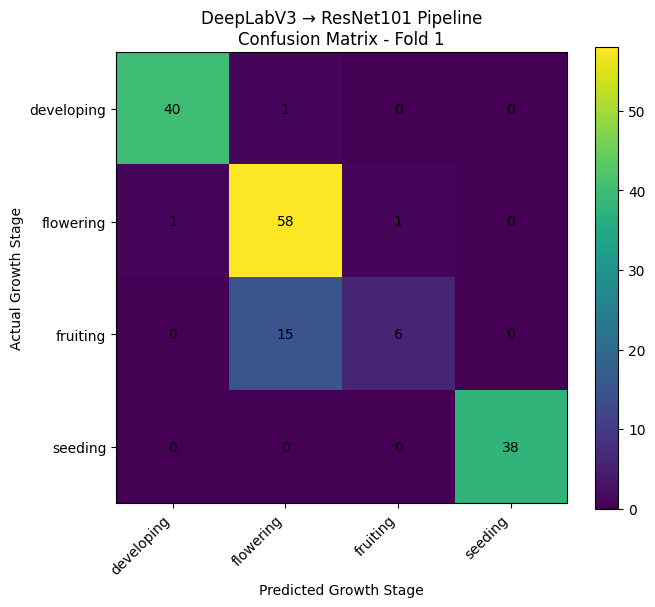

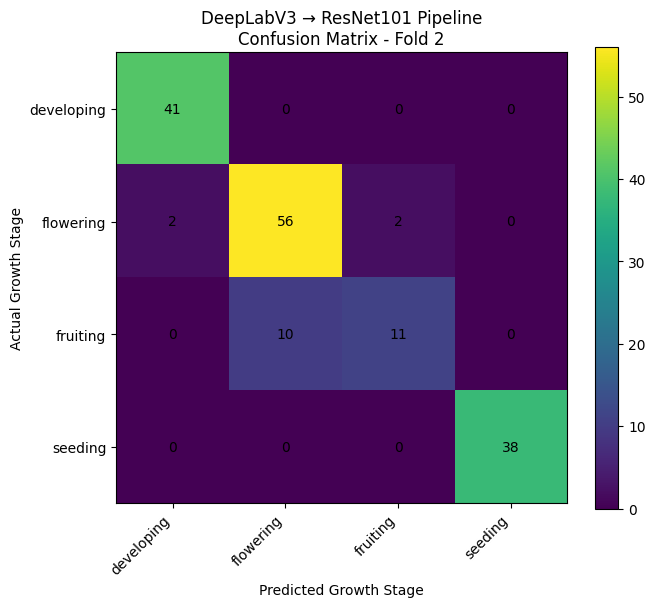

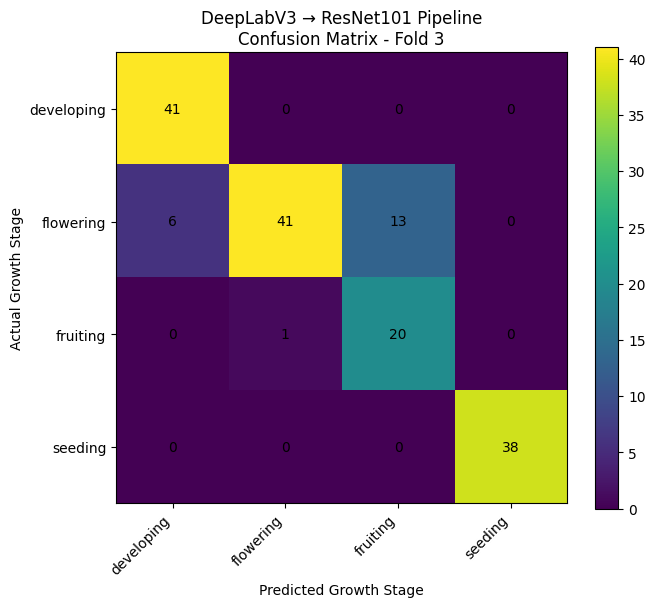

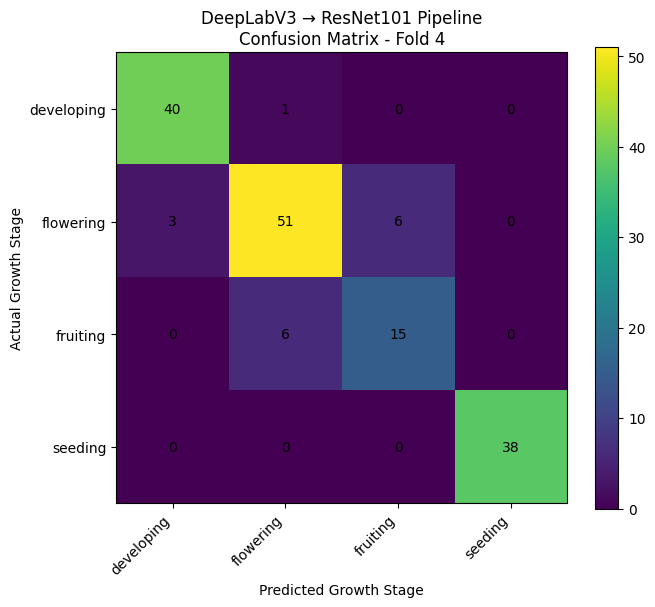

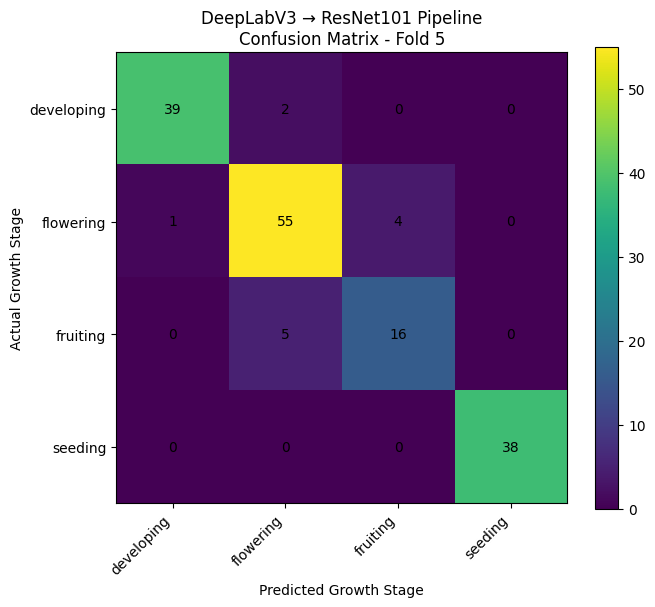

In [ ]:
for fold_number in range(
    1,
    6
):

    cm_path = os.path.join(
        RESULT_DIR,
        (
            f"fold_{fold_number}_"
            "confusion_matrix.npy"
        )
    )


    cm = np.load(
        cm_path
    )


    fig, ax = plt.subplots(
        figsize=(7, 6)
    )


    im = ax.imshow(
        cm
    )


    ax.set_xticks(
        np.arange(
            len(
                CLASS_NAMES
            )
        )
    )


    ax.set_yticks(
        np.arange(
            len(
                CLASS_NAMES
            )
        )
    )


    ax.set_xticklabels(
        CLASS_NAMES,
        rotation=45,
        ha="right"
    )


    ax.set_yticklabels(
        CLASS_NAMES
    )


    ax.set_xlabel(
        "Predicted Growth Stage"
    )


    ax.set_ylabel(
        "Actual Growth Stage"
    )


    ax.set_title(
        (
            "DeepLabV3 → "
            "ResNet101 Pipeline\n"
            f"Confusion Matrix "
            f"- Fold {fold_number}"
        )
    )


    for i in range(
        cm.shape[0]
    ):

        for j in range(
            cm.shape[1]
        ):

            ax.text(
                j,
                i,
                str(
                    cm[
                        i,
                        j
                    ]
                ),
                ha="center",
                va="center"
            )


    fig.colorbar(
        im,
        ax=ax
    )


    plt.tight_layout()


    save_path = os.path.join(
        RESULT_DIR,
        (
            "deeplabv3_"
            "resnet101_"
            f"fold_{fold_number}_"
            "confusion_matrix.png"
        )
    )


    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )


    plt.show()

    plt.close()

In [ ]:
print(
    "=" * 70
)

print(
    "DEEPLABV3 + RESNET101 EXPERIMENT COMPLETED"
)

print(
    "=" * 70
)

print(
    "\nDeepLabV3 checkpoint:"
)

print(
    DEEPLAB_CHECKPOINT
)

print(
    "\nExperiment folder:"
)

print(
    OUTPUT_DIR
)

print(
    "\nResNet101 checkpoints:"
)

for file_name in sorted(
    os.listdir(
        CHECKPOINT_DIR
    )
):

    print(
        "-",
        file_name
    )

print(
    "\nResult files:"
)

for file_name in sorted(
    os.listdir(
        RESULT_DIR
    )
):

    print(
        "-",
        file_name
    )

DEEPLABV3 + RESNET101 EXPERIMENT COMPLETED

DeepLabV3 checkpoint:
/content/drive/MyDrive/tomato_research/deeplabv3_pipeline/checkpoints_segmentation/deeplabv3_leaf_seg_best.pt

Experiment folder:
/content/drive/MyDrive/tomato_research/deeplabv3_pipeline/resnet101_5fold_cv

ResNet101 checkpoints:
- deeplabv3_resnet101_fold_1_best.pth
- deeplabv3_resnet101_fold_2_best.pth
- deeplabv3_resnet101_fold_3_best.pth
- deeplabv3_resnet101_fold_4_best.pth
- deeplabv3_resnet101_fold_5_best.pth

Result files:
- deeplabv3_resnet101_5fold_results.csv
- deeplabv3_resnet101_5fold_summary.csv
- deeplabv3_resnet101_fold_1_confusion_matrix.png
- deeplabv3_resnet101_fold_2_confusion_matrix.png
- deeplabv3_resnet101_fold_3_confusion_matrix.png
- deeplabv3_resnet101_fold_4_confusion_matrix.png
- deeplabv3_resnet101_fold_5_confusion_matrix.png
- deeplabv3_resnet101_training_history.csv
- fold_1_confusion_matrix.npy
- fold_1_predictions.csv
- fold_2_confusion_matrix.npy
- fold_2_predictions.csv
- fold_3_confus